<a href="https://colab.research.google.com/github/AnkaRezaa/machine_learning_254107023002/blob/main/jobsheet%20dataset%20AntiBurnOut/JS02/02_Data_Cleaning_Imputation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS02: Data Cleaning & Missing Value Imputation - Dataset AntiBurnOut

**Identitas Mahasiswa:**
- **Nama**  : MUHAMMAD ANKA REZA
- **NIM**   : 254107023002
- **Kelas** : TI/3H

---

### Deskripsi Praktikum:
Pada praktikum ini dilakukan pembersihan data (*data cleaning*) dan penanganan nilai kosong (*missing values*) menggunakan strategi statistik yang tepat (Median Imputation untuk numerik miring dan Mode Imputation untuk kategorik/teks). Selain itu, dilakukan penanganan outlier serta seleksi fitur tanpa memerlukan pemrosesan citra.

### Langkah 1: Memuat Data dan Pengecekan Missing Values

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

dataset_candidates = [
    'mental_health_burnout_prediction_dataset.csv',
    '../mental_health_burnout_prediction_dataset.csv',
    'jobsheet dataset AntiBurnOut/mental_health_burnout_prediction_dataset.csv'
]
dataset_path = next((p for p in dataset_candidates if os.path.exists(p)), 'mental_health_burnout_prediction_dataset.csv')
df = pd.read_csv(dataset_path)

print("Jumlah missing values sebelum imputasi:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Jumlah missing values sebelum imputasi:
Age                         250
Monthly_Income_USD         1450
Job_Satisfaction            500
Work_Life_Balance           650
Sleep_Hours                 950
Anxiety_Score               800
Depression_Score            850
Mood_Score                  900
Physical_Activity_Hours    1100
Meditation_Minutes         1200
Screen_Time_Hours           850
Social_Media_Hours          600
Gaming_Hours                750
Therapy_Attendance          400
Life_Satisfaction           700
Productivity_Score          950
dtype: int64


### Langkah 2: Imputasi Missing Values
Untuk variabel numerik kontinu, digunakan nilai **Median** agar tahan terhadap *outlier*. Untuk variabel teks/kategorikal, digunakan nilai **Modus** (kategori tersering).

In [2]:
df_clean = df.copy()

# Identifikasi kolom numerik dan kategorik yang memiliki missing value
num_cols_missing = df_clean.select_dtypes(include=['float64', 'int64']).columns[df_clean.select_dtypes(include=['float64', 'int64']).isnull().any()]
cat_cols_missing = df_clean.select_dtypes(include=['object']).columns[df_clean.select_dtypes(include=['object']).isnull().any()]

# 1. Imputasi Numerik dengan Median
for col in num_cols_missing:
    median_val = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_val)

# 2. Imputasi Kategorik dengan Modus
for col in cat_cols_missing:
    mode_val = df_clean[col].mode()[0]
    df_clean[col] = df_clean[col].fillna(mode_val)

print("Verifikasi total missing values setelah imputasi:", df_clean.isnull().sum().sum())

Verifikasi total missing values setelah imputasi: 0


C:\Users\Pongo\AppData\Local\Temp\ipykernel_9056\4015957689.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols_missing = df_clean.select_dtypes(include=['object']).columns[df_clean.select_dtypes(include=['object']).isnull().any()]
C:\Users\Pongo\AppData\Local\Temp\ipykernel_9056\4015957689.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and si

### Langkah 3: Deteksi dan Penanganan Outlier (IQR Method)
Melakukan pemeriksaan outlier pada variabel jam kerja mingguan (`Work_Hours_Per_Week`) dan pendapatan bulanan (`Monthly_Income_USD`).

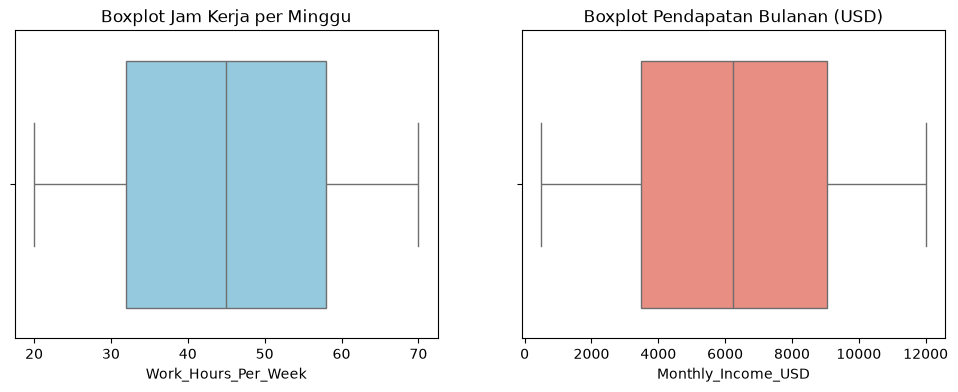

Outlier berhasil ditangani dengan batas ambang IQR.


In [3]:
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
sns.boxplot(x=df_clean['Work_Hours_Per_Week'], color='skyblue')
plt.title('Boxplot Jam Kerja per Minggu')

plt.subplot(1, 2, 2)
sns.boxplot(x=df_clean['Monthly_Income_USD'], color='salmon')
plt.title('Boxplot Pendapatan Bulanan (USD)')
plt.show()

# Capping Outliers dengan batas IQR (Winsorizing)
for col in ['Work_Hours_Per_Week', 'Monthly_Income_USD']:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df_clean[col] = np.clip(df_clean[col], lower_bound, upper_bound)

print("Outlier berhasil ditangani dengan batas ambang IQR.")

### Langkah 4: Seleksi Fitur Dasar (Drop Kolom Non-Informatif)

In [4]:
# Kolom Person_ID merupakan identifier unik yang tidak memiliki nilai prediktif
if 'Person_ID' in df_clean.columns:
    df_clean = df_clean.drop(columns=['Person_ID'])

print("Dimensi dataset bersih siap pakai:", df_clean.shape)

Dimensi dataset bersih siap pakai: (50000, 39)


### Kesimpulan JS02:
1. Nilai kosong pada seluruh 16 fitur numerik dan kategorik berhasil diimputasi tanpa kehilangan satupun baris dari 50.000 sampel data.
2. Penggunaan metode median dan penanganan IQR capping menjaga kestabilan statistik data dari pengaruh nilai ekstrem.